# Multilingual Sentiment: how far does a "multilingual" model really reach?

**The question:** the legacy notebook was a copy of the Hugging Face "quick tour". It loaded `nlptown/bert-base-multilingual-uncased-sentiment`, a BERT model that turns a product review into 1 to 5 stars, classified a handful of sentences, and declared that it "can deal with texts in English, French, but also Dutch, German, Italian and Spanish". That claim was never tested. *How accurate is the model in each language? Does it work in languages it was not trained on (Japanese and Chinese)? Would an English-only sentiment model do? And can a simple model trained on 5,000 reviews in the same language beat it?* We test on **30,000 real Amazon product reviews, 5,000 in each of six languages**, with exactly 1,000 reviews per star rating.

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit: the reviews
4. Hypotheses and why we chose each test
5. The models
6. H1: how good is it, language by language?
7. H2: does an English-only model transfer?
8. H3: what do the mistakes look like?
9. H4: does a small model trained on the language beat it?
10. Takeaways
11. Limitations

**Run it:** `uv run jupyter lab NLP/multilingual-sentiment-bert/multilingual_sentiment_bert.ipynb`, or *Run All* in any Jupyter. The reviews (about 15 MB) and the two models (about 1 GB in total) download themselves on the first run. It uses a GPU if present and takes about 10 minutes on one.

## 1. 💡 The simple analogy

Imagine a **hotel concierge who has read thousands of guest comments in six languages** and is asked to guess the star rating a guest gave.

- In the languages he studied, he is good: usually right to within a star, though "4 stars or 5?" is a coin flip, even for people.
- Hand him a comment in **a language he never studied** (Japanese, Chinese) and he does something clever but clumsy: he recognises a few cheerful or angry words and shapes, so he is better than guessing, but his answers drift toward the middle.
- A **colleague who only reads English** is hopeless on a German comment: he sees unknown words and guesses.
- And a **local trainee who has read 5,000 comments in that one language** can quietly beat the polyglot where the polyglot has no training.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the maximum review length (128 word-pieces) and the list of languages keeps the notebook reproducible and avoids "magic numbers". The model card says the star model was trained on English, Dutch, German, French, Spanish and Italian, so for our six test languages **English, German, Spanish and French are "trained on" and Japanese and Chinese are "not trained on"**.

In [1]:
# ruff: noqa: E402 (the settings below must come before the imports that read them)
import os
import warnings

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore", message="IProgress not found")
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from huggingface_hub import snapshot_download
from huggingface_hub.utils import logging as hub_logging
from scipy import stats
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from statsmodels.stats.contingency_tables import mcnemar
from transformers import AutoModelForSequenceClassification, AutoTokenizer
from transformers.utils import logging as hf_logging

hub_logging.set_verbosity_error()
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
STARS_MODEL = "nlptown/bert-base-multilingual-uncased-sentiment"
ENGLISH_MODEL = "distilbert-base-uncased-finetuned-sst-2-english"
LANGS = ["en", "de", "es", "fr", "ja", "zh"]
TRAINED_ON = {"en", "de", "es", "fr"}  # languages the star model was trained on (model card)
LANG_NAMES = {
    "en": "English",
    "de": "German",
    "es": "Spanish",
    "fr": "French",
    "ja": "Japanese",
    "zh": "Chinese",
}
SEED = 365
MAX_LEN = 128
N_BOOTSTRAP = 1_000
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if float(p) < 1e-300 else f"{float(p):.1e}"

## 3. Audit: the reviews

*What:* the **Multilingual Amazon Reviews Corpus**: product reviews in English, German, Spanish, French, Japanese and Chinese with a 1 to 5 star rating. We use the **test** split (5,000 reviews per language, exactly 1,000 per star) for all scoring, and the **validation** split (another 5,000 per language) only as a small training set for the simple baseline in H4. We check lengths (in the model's word-pieces), duplicates and overlap between the two splits. *Why:* a language can look hard just because its reviews are longer or are cut off more often.

> **Problems in the legacy notebook this replaces:** it is a copy of the library's tour: it classified a handful of invented sentences, never measured accuracy in any language, mixed in a TensorFlow conversion of a PyTorch-only model, and "tested" the model on `"I am a good boy"`.

In [2]:
if not (DATA_DIR / "amazon" / "en" / "test.jsonl").exists():
    snapshot_download(
        "mteb/amazon_reviews_multi",
        repo_type="dataset",
        local_dir=DATA_DIR / "amazon",
        allow_patterns=["*/test.jsonl", "*/validation.jsonl"],
    )


def read_split(lang: str, split: str) -> pd.DataFrame:
    """Reads one language's reviews; ``stars`` runs from 1 to 5."""
    path = DATA_DIR / "amazon" / lang / f"{split}.jsonl"
    rows = [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines()]
    table = pd.DataFrame(rows)[["id", "text", "label"]]
    table["stars"] = table["label"] + 1
    return table


test = {lang: read_split(lang, "test") for lang in LANGS}
small_train = {lang: read_split(lang, "validation") for lang in LANGS}
tokenizer = AutoTokenizer.from_pretrained(STARS_MODEL)
rows = []
for lang in LANGS:
    texts = test[lang]["text"]
    pieces = np.array([len(i) for i in tokenizer(list(texts))["input_ids"]])
    rows.append(
        {
            "language": LANG_NAMES[lang],
            "reviews": len(texts),
            "per star": int(test[lang]["stars"].value_counts().min()),
            "characters (median)": int(texts.str.len().median()),
            "word-pieces (median)": int(np.median(pieces)),
            f"cut at {MAX_LEN} pieces": f"{(pieces > MAX_LEN).mean():.0%}",
            "duplicate texts": int(texts.duplicated().sum()),
            "trained on": "yes" if lang in TRAINED_ON else "no",
        }
    )
audit = pd.DataFrame(rows).set_index("language")
print(audit.to_string())
print(f"\nExample (zh, 1 star): {test['zh'].query('stars == 1')['text'].iloc[0][:80]!r}")
overlap = sum(len(set(test[lang]["text"]) & set(small_train[lang]["text"])) for lang in LANGS)
print(f"Reviews that appear in both the test and the small training set: {overlap}")

          reviews  per star  characters (median)  word-pieces (median) cut at 128 pieces  duplicate texts trained on
language                                                                                                            
English      5000      1000                  156                    40                5%                0        yes
German       5000      1000                  179                    46                7%                0        yes
Spanish      5000      1000                  142                    37                3%                0        yes
French       5000      1000                  145                    39                4%                0        yes
Japanese     5000      1000                   83                    66               18%                0         no
Chinese      5000      1000                   47                    46                6%                0         no

Example (zh, 1 star): '假货\n\n买的两百多的，不是真货，和真的对比了小一圈！特别不好跟30多元的没区

**How to read this:**

- **A balanced exam:** 5,000 test reviews per language, **1,000 per star**, so a guesser who always says "5 stars" gets 20% of them exactly right. No duplicate texts within a language's test set.
- **Reviews are short:** the median is **37 to 46** word-pieces in the European languages, **66** in Japanese and **46** in Chinese. Only **3% to 7%** are cut at 128 pieces in the European languages and Chinese, but **18% of the Japanese reviews are cut**, because Japanese text splits into more word-pieces; the star model sees only the start of those.
- **A tiny overlap:** **9** reviews appear in both the test set and the small training set, out of 30,000; it is too small to matter.

## 4. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Is the star model equally accurate in all six languages, and as accurate in the two it was not trained on? | Same accuracy | It differs, with a drop for Japanese and Chinese | Exact-star accuracy with bootstrap CIs; chi-square across languages; trained-on versus not-trained-on difference with a bootstrap CI |
| H2 | Does an English-only sentiment model transfer to the other languages? | Same ability to tell bad from good reviews | It is worse outside English | AUC for 1-2 star versus 4-5 star reviews, for both models, with paired bootstrap difference |
| H3 | Are the star model's mistakes of the same kind in every language? | Same | Different | Share of errors that are one star off, large (3+ star) errors, and the confusion matrices |
| H4 | Does a simple model trained on 5,000 reviews in the language beat the pretrained model? | Same accuracy | Differs by language | Exact McNemar test on the same reviews; AUC |

*Why these tests?* All models score the **same reviews**, so the exact **McNemar test**, which looks only at the reviews where two models disagree, is the right comparison for accuracy. For "good versus bad" the **AUC** (the chance that a randomly chosen good review scores higher than a randomly chosen bad one; 0.5 is chance) does not depend on a threshold, so it is fair to a model that was built for a different scale.

## 5. The models

*What:* two pretrained models and one small trained one.

- **The star model** (`nlptown/bert-base-multilingual-uncased-sentiment`): BERT with a 5-way output (1 to 5 stars), trained on product reviews in six languages. Its **predicted rating** is the most likely star; its **expected rating** is the probability-weighted average of the stars (used for AUC).
- **The English-only model** (`distilbert-base-uncased-finetuned-sst-2-english`): DistilBERT fine-tuned on English movie sentences to say positive or negative. Its score is the probability of "positive".
- **The small baseline** (H4): character 1-4-gram TF-IDF with logistic regression, trained on 5,000 reviews of each language (no word splitter is needed, so it works for Japanese and Chinese).

Reviews are cut to the first **128 word-pieces**, sorted by length to need little padding, and the original order is restored.

In [3]:
def softmax_scores(model_name: str, texts: list[str], batch: int = 128) -> np.ndarray:
    """Runs a sequence classifier over reviews and returns class probabilities.

    Reviews are sorted by length so batches need little padding; the original order is restored.

    Args:
        model_name: A Hugging Face model id.
        texts: The reviews.
        batch: Reviews per forward pass.

    Returns:
        Probabilities, shape (n, number of classes).
    """
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name).to(DEVICE).eval()
    order = np.argsort([len(t) for t in texts])
    out = np.zeros((len(texts), model.config.num_labels), np.float32)
    with torch.no_grad():
        for start in range(0, len(texts), batch):
            pick = order[start : start + batch]
            enc = tok(
                [texts[i] for i in pick],
                padding=True,
                truncation=True,
                max_length=MAX_LEN,
                return_tensors="pt",
            ).to(DEVICE)
            out[pick] = torch.softmax(model(**enc).logits, dim=1).cpu().numpy()
    del model
    torch.cuda.empty_cache()
    return out


star_probs = {lang: softmax_scores(STARS_MODEL, test[lang]["text"].tolist()) for lang in LANGS}
english_probs = {
    lang: softmax_scores(ENGLISH_MODEL, test[lang]["text"].tolist())[:, 1] for lang in LANGS
}
labels = AutoModelForSequenceClassification.from_pretrained(STARS_MODEL).config.id2label
print("Star model outputs:", labels)
for lang in LANGS:
    test[lang]["pred"] = star_probs[lang].argmax(1) + 1
    test[lang]["expected"] = star_probs[lang] @ np.arange(1, 6)
print(f"Scored {sum(len(t) for t in test.values()):,} reviews with each model.")

Star model outputs: {0: '1 star', 1: '2 stars', 2: '3 stars', 3: '4 stars', 4: '5 stars'}
Scored 30,000 reviews with each model.


**How to read this:** the star model outputs five classes (`1 star` to `5 stars`) and all **30,000** test reviews are scored by both pretrained models.

## 6. H1: how good is it, language by language?

*What:* for each language, the share of reviews whose star rating is predicted **exactly**, the share predicted **within one star**, the average error in stars and the Spearman correlation between the model's expected rating and the true stars. We test whether accuracy differs across languages (chi-square), and compare the four trained-on languages with Japanese and Chinese pooled, with a bootstrap interval for the difference. *Why:* this is the claim the legacy notebook made without checking.

In [4]:
def bootstrap(metric, *arrays: np.ndarray) -> tuple[float, float, float]:
    """A metric with a 95% bootstrap interval that resamples reviews.

    Args:
        metric: A function of the arrays returning a number.
        *arrays: Arrays of equal length (resampled together).

    Returns:
        The metric, and the 2.5th and 97.5th percentiles over resamples.
    """
    values = []
    for _ in range(N_BOOTSTRAP):
        pick = rng.integers(0, len(arrays[0]), len(arrays[0]))
        values.append(metric(*[a[pick] for a in arrays]))
    return metric(*arrays), *np.percentile(values, [2.5, 97.5])


def exact(truth: np.ndarray, pred: np.ndarray) -> float:
    """Share of reviews whose star rating is predicted exactly."""
    return float((truth == pred).mean())


def within_one(truth: np.ndarray, pred: np.ndarray) -> float:
    """Share of reviews predicted within one star."""
    return float((np.abs(truth - pred) <= 1).mean())


rows = []
for lang in LANGS:
    t, p = test[lang]["stars"].to_numpy(), test[lang]["pred"].to_numpy()
    acc, lo, hi = bootstrap(exact, t, p)
    rows.append(
        {
            "language": LANG_NAMES[lang],
            "exact": acc,
            "ci_low": lo,
            "ci_high": hi,
            "within one star": within_one(t, p),
            "mean error (stars)": np.abs(t - p).mean(),
            "Spearman": stats.spearmanr(t, test[lang]["expected"]).statistic,
            "trained on": lang in TRAINED_ON,
        }
    )
star_table = pd.DataFrame(rows).set_index("language")
print(star_table.round(3).to_string())
counts = np.array(
    [
        [(test[g]["stars"] == test[g]["pred"]).sum(), (test[g]["stars"] != test[g]["pred"]).sum()]
        for g in LANGS
    ]
)
chi2, p_lang, _, _ = stats.chi2_contingency(counts)
print(f"\nExact accuracy differs across the six languages: chi-square p = {fmt_p(p_lang)}")
seen = pd.concat([test[g] for g in LANGS if g in TRAINED_ON])
unseen = pd.concat([test[g] for g in LANGS if g not in TRAINED_ON])
a, b = (seen["stars"] == seen["pred"]).to_numpy(), (unseen["stars"] == unseen["pred"]).to_numpy()
diffs = [rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(N_BOOTSTRAP)]
print(
    f"Languages it was trained on: {a.mean():.1%} exact; Japanese and Chinese: {b.mean():.1%}; "
    f"difference {a.mean() - b.mean():+.1%} (95% CI {np.percentile(diffs, 2.5):+.1%} to "
    f"{np.percentile(diffs, 97.5):+.1%})"
)

          exact  ci_low  ci_high  within one star  mean error (stars)  Spearman  trained on
language                                                                                   
English   0.636   0.622    0.649            0.944               0.433     0.876        True
German    0.640   0.626    0.653            0.958               0.409     0.893        True
Spanish   0.595   0.582    0.608            0.950               0.464     0.876        True
French    0.593   0.579    0.606            0.949               0.468     0.875        True
Japanese  0.377   0.364    0.390            0.766               0.949     0.551       False
Chinese   0.385   0.371    0.398            0.752               0.980     0.660       False

Exact accuracy differs across the six languages: chi-square p = < 1e-300
Languages it was trained on: 61.6% exact; Japanese and Chinese: 38.1%; difference +23.5% (95% CI +22.3% to +24.7%)


**How to read this:**

- **In the languages it knows, the model is good but far from perfect:** exact accuracy is **63.6%** (English, CI 62.2% to 64.9%), **64.0%** (German), **59.5%** (Spanish) and **59.3%** (French), against 20% for guessing. It is within one star for **94% to 96%** of the reviews, and the Spearman correlation with the true stars is **0.88 to 0.89**.
- **In Japanese and Chinese it drops sharply:** exact accuracy is **37.7%** and **38.5%**, within one star **76.6%** and **75.2%**, with an average error of **0.95** and **0.98** stars (against 0.41 to 0.47 for the others) and Spearman **0.55** and **0.66**. It is still well above chance, a sign of some transfer from its multilingual BERT base.
- **The differences are real:** the chi-square test across the six languages gives p below 1e-300 (the smallest number the computer can show). The four trained-on languages together score **61.6%** against **38.1%** for the two others, a difference of **+23.5 points** (95% CI +22.3 to +24.7). **We reject H₀.**
- **The star model is not equally good across the languages it knows,** either: German is 4.7 points ahead of French, a gap larger than the bootstrap intervals (about ±1.3 points).

## 7. H2: does an English-only model transfer?

*What:* ignore the 3-star reviews and ask how well each model separates **bad (1-2 stars) from good (4-5 stars)** reviews, with the AUC, per language, with 95% bootstrap intervals and a paired bootstrap interval for the difference. The star model's score is its expected rating; the English-only model's is the probability of "positive". *Why:* it checks the "just use the English sentiment model" shortcut, and separates the star model's language skill from the difficulty of the task.

In [5]:
rows = []
for lang in LANGS:
    keep = (test[lang]["stars"] != 3).to_numpy()
    truth = (test[lang]["stars"].to_numpy()[keep] >= 4).astype(int)
    multi, english = test[lang]["expected"].to_numpy()[keep], english_probs[lang][keep]
    auc_m, lo_m, hi_m = bootstrap(roc_auc_score, truth, multi)
    auc_e, lo_e, hi_e = bootstrap(roc_auc_score, truth, english)
    diff = bootstrap(
        lambda t, x, z: roc_auc_score(t, x) - roc_auc_score(t, z), truth, multi, english
    )
    rows.append(
        {
            "language": LANG_NAMES[lang],
            "multilingual AUC": auc_m,
            "m_low": lo_m,
            "m_high": hi_m,
            "English-only AUC": auc_e,
            "e_low": lo_e,
            "e_high": hi_e,
            "difference": diff[0],
            "d_low": diff[1],
            "d_high": diff[2],
        }
    )
binary = pd.DataFrame(rows).set_index("language")
print(binary.round(3).to_string())

          multilingual AUC  m_low  m_high  English-only AUC  e_low  e_high  difference  d_low  d_high
language                                                                                             
English              0.983  0.979   0.986             0.945  0.938   0.952       0.038  0.032   0.044
German               0.989  0.986   0.991             0.584  0.565   0.600       0.405  0.388   0.422
Spanish              0.988  0.986   0.991             0.811  0.798   0.823       0.177  0.164   0.191
French               0.986  0.983   0.990             0.698  0.682   0.714       0.289  0.274   0.305
Japanese             0.828  0.815   0.840             0.510  0.491   0.527       0.318  0.297   0.339
Chinese              0.880  0.870   0.891             0.536  0.517   0.555       0.345  0.323   0.365


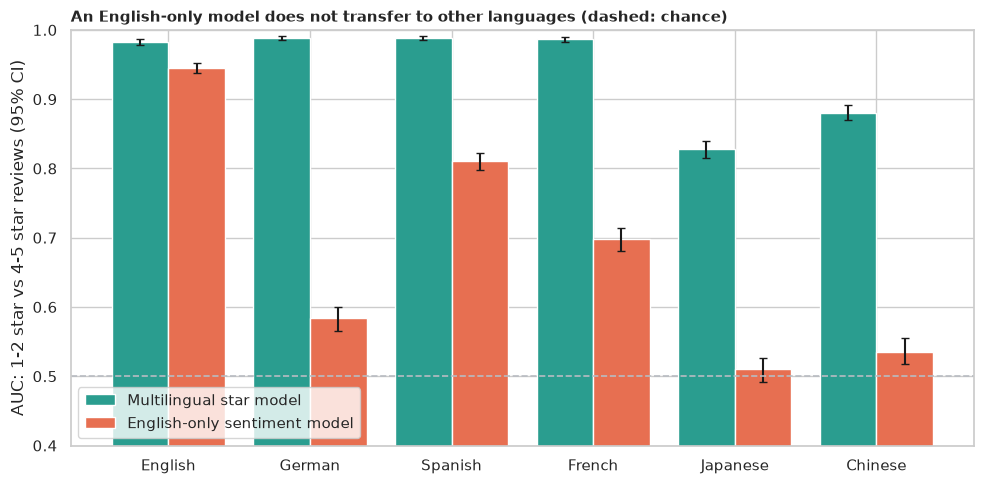

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(LANGS))
for shift, col, color, label in [
    (-0.2, "multilingual", TEAL, "Multilingual star model"),
    (0.2, "English-only", ORANGE, "English-only sentiment model"),
]:
    prefix = col[0].lower()
    ax.bar(
        x + shift,
        binary[f"{col} AUC"],
        0.4,
        color=color,
        label=label,
        yerr=[
            binary[f"{col} AUC"] - binary[f"{prefix}_low"],
            binary[f"{prefix}_high"] - binary[f"{col} AUC"],
        ],
        capsize=3,
    )
ax.axhline(0.5, color=GREY, ls="--", lw=1.2)
ax.set_xticks(x, [LANG_NAMES[g] for g in LANGS])
ax.set_ylim(0.4, 1.0)
ax.set_ylabel("AUC: 1-2 star vs 4-5 star reviews (95% CI)")
ax.set_title(
    "An English-only model does not transfer to other languages (dashed: chance)",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(OUT_DIR / "02_english_vs_multilingual.png", dpi=150)
plt.show()

**How to read this:**

- **The star model separates good from bad reviews very well in the languages it knows:** AUC **0.983** (English), **0.989** (German), **0.988** (Spanish) and **0.986** (French). In Japanese it is **0.828** (CI 0.815 to 0.840) and in Chinese **0.880** (0.870 to 0.891): worse, but far above the chance level of 0.5.
- **The English-only model does well on English only:** AUC **0.945** in English (about 0.04 below the star model, which was trained on product reviews), but **0.811** in Spanish, **0.698** in French, **0.584** in German, **0.536** in Chinese and **0.510** in Japanese (chance is 0.5). It fails entirely on languages that do not share its words.
- **The multilingual model wins in every language:** the AUC difference is **+0.038** (English), **+0.405** (German), **+0.177** (Spanish), **+0.289** (French), **+0.318** (Japanese) and **+0.345** (Chinese), with all 95% intervals far from 0. **We reject H₀.**
- A likely reason (not tested here) is that Spanish and French share more words with English than German does, so an English vocabulary helps them a little.

## 8. H3: what do the mistakes look like?

*What:* for each language, the share of the errors that are exactly one star off, the share of **all** reviews that are 3 or more stars off (a 1-star review called 4 or 5, or the reverse), whether errors lean low or high, and the average predicted rating for true 1-star and 5-star reviews. The figure shows the confusion matrix for each language (each row is the true rating, each column the prediction, in percent). *Why:* "wrong" is not one thing: "4 stars or 5?" is a shrug and "1 star or 5?" is a disaster.

          wrong  adjacent star (share of errors)  3+ stars off (share of reviews)  predicts too low  mean prediction for 1-star  mean prediction for 5-star
language                                                                                                                                                   
English   0.364                            0.847                            0.010             0.583                       1.265                       4.730
German    0.360                            0.883                            0.006             0.536                       1.251                       4.834
Spanish   0.405                            0.876                            0.007             0.572                       1.219                       4.650
French    0.407                            0.875                            0.008             0.541                       1.275                       4.685
Japanese  0.623                            0.625                

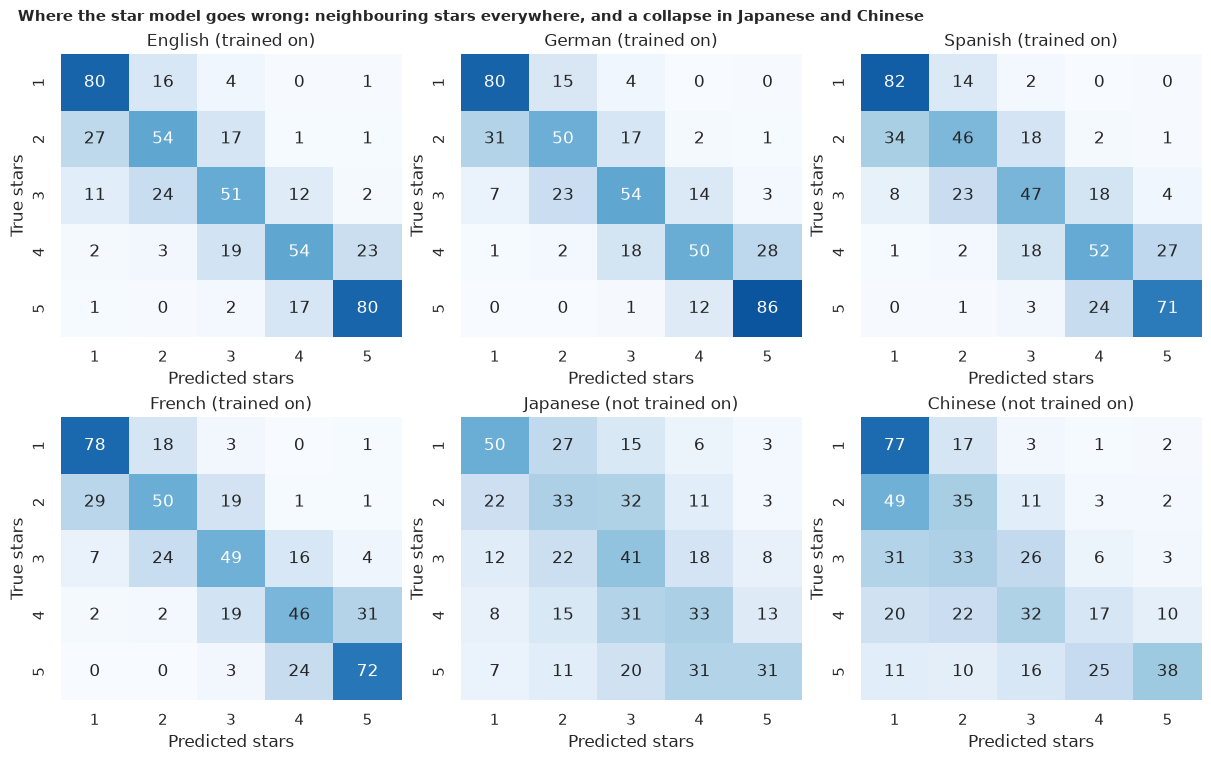

In [7]:
rows = []
for lang in LANGS:
    err = test[lang]["pred"] - test[lang]["stars"]
    wrong = err != 0
    rows.append(
        {
            "language": LANG_NAMES[lang],
            "wrong": wrong.mean(),
            "adjacent star (share of errors)": (err.abs() == 1)[wrong].mean(),
            "3+ stars off (share of reviews)": (err.abs() >= 3).mean(),
            "predicts too low": (err < 0)[wrong].mean(),
            "mean prediction for 1-star": test[lang].query("stars == 1")["pred"].mean(),
            "mean prediction for 5-star": test[lang].query("stars == 5")["pred"].mean(),
        }
    )
errors = pd.DataFrame(rows).set_index("language")
print(errors.round(3).to_string())
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5), layout="constrained")
for ax, lang in zip(axes.ravel(), LANGS, strict=True):
    cm = pd.crosstab(test[lang]["stars"], test[lang]["pred"], normalize="index")
    cm = cm.reindex(index=range(1, 6), columns=range(1, 6), fill_value=0)
    sns.heatmap(cm * 100, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=ax, vmin=0, vmax=100)
    ax.set_title(
        LANG_NAMES[lang] + (" (trained on)" if lang in TRAINED_ON else " (not trained on)")
    )
    ax.set_xlabel("Predicted stars")
    ax.set_ylabel("True stars")
fig.suptitle(
    "Where the star model goes wrong: neighbouring stars everywhere, and a collapse "
    "in Japanese and Chinese",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.savefig(OUT_DIR / "03_confusion.png", dpi=150)
plt.show()

**How to read this:**

- **In the trained-on languages the mistakes are neighbours:** **85% to 88%** of the errors are exactly one star off, and only **0.6% to 1.0%** of all reviews are off by 3 stars or more. The average prediction for true 1-star reviews is about **1.2 to 1.3** and for 5-star reviews **4.65 to 4.83**.
- **In Japanese and Chinese the model is both less accurate and less decisive:** only **62%** and **60%** of the errors are one star off, **7.3%** and **9.1%** of all reviews are 3 or more stars off, and the mean prediction for true 5-star reviews falls to **3.69** and **3.68** (the model hedges toward the middle). In Chinese, **81%** of all its errors are predictions that are too low (54% to 58% in the other languages).
- **Japanese 1-star reviews fare especially badly:** their mean prediction is **1.84** (against 1.22 to 1.33 elsewhere), possibly related to the 18% of Japanese reviews that are cut at 128 pieces (we did not test it).
- **We reject H₀:** the mix of errors depends strongly on whether the language was trained on.

## 9. H4: does a small model trained on the language beat it?

*What:* train a **character n-gram TF-IDF + logistic regression** on the 5,000 validation reviews of each language and score it on the same test reviews. We compare exact star accuracy (exact McNemar test per language) and the good-versus-bad AUC. *Why:* a "no training needed" model must be compared with a cheap model that does use local data, which the legacy notebook never did.

In [8]:
def make_tfidf() -> Pipeline:
    """Character n-gram TF-IDF with logistic regression; needs no tokenizer for any script."""
    return Pipeline(
        [
            (
                "vec",
                TfidfVectorizer(
                    analyzer="char_wb",
                    ngram_range=(1, 4),
                    min_df=3,
                    sublinear_tf=True,
                    max_features=200_000,
                ),
            ),
            ("clf", LogisticRegression(C=10, max_iter=2000)),
        ]
    )


rows = []
for lang in LANGS:
    train = small_train[lang]
    model = make_tfidf().fit(train["text"], train["stars"])
    prob = model.predict_proba(test[lang]["text"])
    test[lang]["tfidf_pred"] = model.classes_[prob.argmax(1)]
    test[lang]["tfidf_expected"] = prob @ model.classes_
    t = test[lang]["stars"].to_numpy()
    acc_s, lo_s, hi_s = bootstrap(exact, t, test[lang]["pred"].to_numpy())
    acc_t, lo_t, hi_t = bootstrap(exact, t, test[lang]["tfidf_pred"].to_numpy())
    right_s, right_t = t == test[lang]["pred"].to_numpy(), t == test[lang]["tfidf_pred"].to_numpy()
    mc = mcnemar(
        [
            [int((right_s & right_t).sum()), int((right_s & ~right_t).sum())],
            [int((~right_s & right_t).sum()), int((~right_s & ~right_t).sum())],
        ],
        exact=True,
    )
    keep = t != 3
    auc_s = roc_auc_score(t[keep] >= 4, test[lang]["expected"].to_numpy()[keep])
    auc_t = roc_auc_score(t[keep] >= 4, test[lang]["tfidf_expected"].to_numpy()[keep])
    rows.append(
        {
            "language": LANG_NAMES[lang],
            "star model": acc_s,
            "s_low": lo_s,
            "s_high": hi_s,
            "TF-IDF (5,000 reviews)": acc_t,
            "t_low": lo_t,
            "t_high": hi_t,
            "star right only": int((right_s & ~right_t).sum()),
            "TF-IDF right only": int((~right_s & right_t).sum()),
            "McNemar p": mc.pvalue,
            "AUC star model": auc_s,
            "AUC TF-IDF": auc_t,
        }
    )
versus = pd.DataFrame(rows).set_index("language")
shown = versus.copy()
shown["McNemar p"] = shown["McNemar p"].map(fmt_p)
print(shown.drop(columns=["s_low", "s_high", "t_low", "t_high"]).round(3).to_string())

          star model  TF-IDF (5,000 reviews)  star right only  TF-IDF right only McNemar p  AUC star model  AUC TF-IDF
language                                                                                                              
English        0.636                   0.513             1111                496   2.9e-54           0.983       0.944
German         0.640                   0.502             1211                521   3.1e-63           0.989       0.953
Spanish        0.595                   0.468             1195                560   7.0e-53           0.988       0.952
French         0.593                   0.479             1157                588   7.6e-43           0.986       0.955
Japanese       0.377                   0.478              807               1312   3.8e-28           0.828       0.951
Chinese        0.385                   0.468              742               1157   1.5e-21           0.880       0.926


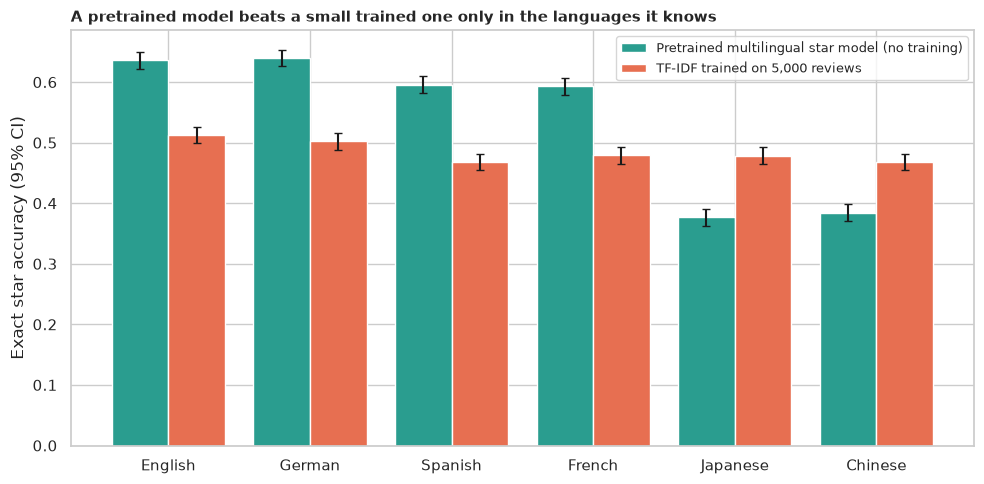

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(LANGS))
for shift, col, prefix, color, label in [
    (-0.2, "star model", "s", TEAL, "Pretrained multilingual star model (no training)"),
    (0.2, "TF-IDF (5,000 reviews)", "t", ORANGE, "TF-IDF trained on 5,000 reviews"),
]:
    ax.bar(
        x + shift,
        versus[col],
        0.4,
        color=color,
        label=label,
        yerr=[versus[col] - versus[f"{prefix}_low"], versus[f"{prefix}_high"] - versus[col]],
        capsize=3,
    )
ax.set_xticks(x, [LANG_NAMES[g] for g in LANGS])
ax.set_ylabel("Exact star accuracy (95% CI)")
ax.set_title(
    "A pretrained model beats a small trained one only in the languages it knows",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_star_accuracy.png", dpi=150)
plt.show()

**How to read this:**

- **In the trained-on languages the star model wins clearly:** exact accuracy **63.6% against 51.3%** (English), **64.0% against 50.2%** (German), **59.5% against 46.8%** (Spanish) and **59.3% against 47.9%** (French). It gets 1,111 to 1,211 reviews right that the small model gets wrong and loses 496 to 588 (McNemar p from 3e-54 to 8e-43). The AUC is **0.983 to 0.989** against **0.944 to 0.955**.
- **In Japanese and Chinese the small model wins:** exact accuracy **47.8% against 37.7%** (Japanese) and **46.8% against 38.5%** (Chinese); it gets 1,312 and 1,157 reviews right that the star model gets wrong and loses 807 and 742 (p = 4e-28 and 2e-21). The AUC is **0.951 against 0.828** (Japanese) and **0.926 against 0.880** (Chinese).
- **A pretrained model is only as good as the languages it was trained on:** with 5,000 labelled reviews a plain bag-of-characters model overtakes it where the pretraining did not reach. **We reject H₀.**
- Note that the small model is cheap to train, but the star model needed none: the right choice depends on whether you have labelled data in your language.

## 10. 🎯 Takeaways

1. **"Multilingual" has a boundary:** the star model gets 59% to 64% of the stars exactly right (94% to 96% within one star) in the languages it was trained on, and only 38% (75% to 77% within one star) in Japanese and Chinese, a drop of 23.5 points (CI +22.3 to +24.7).
2. **An English-only model is not a multilingual model:** its good-versus-bad AUC is 0.945 in English but 0.584 in German and 0.510 in Japanese (chance is 0.5); the star model reaches 0.98 to 0.99 in the languages it knows.
3. **Mistakes differ in kind:** in known languages 85% to 88% of the errors are one star off; in Japanese and Chinese 7% to 9% of all reviews are three or more stars off, and the model hedges toward the middle.
4. **A small local model can beat a big foreign one:** trained on 5,000 reviews, a character n-gram TF-IDF model beats the star model in Japanese (47.8% against 37.7% exact; AUC 0.951 against 0.828) and Chinese (46.8% against 38.5%).
5. **Know what the model was trained on before you trust a claim like "supports 6 languages":** test it, per language, on data it has not seen.

## 11. ⚠️ Limitations

- **One domain:** Amazon product reviews. The star model was trained on product reviews, so it is at home here; results for tweets, news or hotel reviews will differ.
- **Possible contamination:** the training data of the star model are described only as product reviews in six languages; some of these test reviews could have been seen in training, which would flatter the trained-on languages.
- **Reviews are cut at 128 word-pieces,** which hurts Japanese most (18% cut). A longer limit would help the star model, at a higher cost.
- **The small baseline is deliberately simple:** one configuration (character 1-4-grams, C = 10), no tuning, 5,000 training reviews. A tuned or fine-tuned model would do better.
- **Two languages not trained on:** Japanese and Chinese differ from the trained-on languages in script and structure as well as in training, so the 23.5-point drop mixes both.
- **"Trained on" comes from the model card** and was not verified.
- **Stars are a coarse, noisy label:** the same words can earn 4 or 5 stars, so exact accuracy has a ceiling well below 100%.
- **The English-only model was built for binary movie sentiment,** so its comparison is about transfer, not about the best English model.